# 02 · Mô hình Baseline: Persistence & Linear Regression

**Bài toán:** dự đoán nồng độ PM2.5 (µg/m³) ở **giờ kế tiếp (t+1)** của cùng một trạm, từ dữ liệu đến giờ t.

**Mục tiêu của notebook này:** tạo ra "mốc so sánh" mà Random Forest / Gradient Boosting (notebook 03) phải vượt qua. Có hai baseline:

| # | Baseline | Ý tưởng | Có học từ dữ liệu không? |
|:-:|---|---|:-:|
| 1 | **Persistence** | dự đoán PM2.5(t+1) = PM2.5(t), tức "giờ sau giống giờ trước" | Không |
| 2 | **Linear Regression** | hồi quy tuyến tính trên toàn bộ feature của pipeline chung (có `StandardScaler`) | Có |

Persistence quan trọng ở chỗ nó trả lời câu hỏi *"mô hình có thật sự học được gì hơn việc lặp lại giá trị gần nhất không?"* (proposal, mục 6).

### Quy ước đã chốt trong README/proposal mà notebook tuân thủ

- Chia **theo thời gian**, không xáo trộn: train/validation có nhãn đến 08/2016, **test từ 01/09/2016** (chia theo `target_datetime`).
- Validation bằng **`TimeSeriesSplit` expanding-window, 5 fold**; các trạm cùng một giờ nhãn luôn nằm cùng một phía của fold (hàm `cv_folds` đã lo).
- Mọi bước tiền xử lý (median, scaler, one-hot, cờ missing) **chỉ fit trên phần train** của từng fold. Ở đây ta dùng `build_preprocessor(scale=True)` của `src/features.py` nên đã đúng sẵn.
- Không điền target bị thiếu; các dòng thiếu target bị loại **sau khi** đã tạo lag/feature.
- Độ đo: **MAE, RMSE, R²**. **RMSE trên validation** là độ đo chính để chọn mô hình. Báo cáo thêm theo **trạm, mùa, mức PM2.5**.
- Chỉ **StandardScaler cho Linear Regression** (mô hình cây không cần).

### Sản phẩm notebook này tạo ra

| Tệp | Nội dung |
|---|---|
| `models/baseline_linear_regression.joblib` | pipeline Linear Regression đã fit trên toàn bộ train/validation |
| `models/baseline_metrics.csv` | bảng tóm tắt MAE/RMSE/R² của các baseline (CV và test) |
| `models/baseline_metadata.json` | thông tin để nạp lại/truy vết mô hình (feature, mốc thời gian, phiên bản sklearn) |
| `outputs/baseline_error_analysis.csv` | sai số theo trạm / mùa / mức PM2.5 |
| `outputs/figures/baseline_*.png` | các biểu đồ |
| `experiment_log.csv` | thêm các dòng baseline (chạy lại không bị trùng dòng) |

> **Cách chạy:** `Kernel → Restart & Run All`. Chạy từ thư mục gốc repo hay từ `notebooks/` đều được. Thời gian khoảng 1–2 phút.

## 1. Cấu hình môi trường

Ô dưới đây nạp thư viện, tự tìm thư mục gốc của repo (để `from src... import ...` chạy được dù bạn mở notebook từ đâu) và đặt hai cờ cấu hình:

- `SAVE_ARTIFACTS`: `True` thì ghi mô hình, bảng và hình ra đĩa. Đặt `False` nếu chỉ muốn chạy thử.
- `RUN_FINAL_TEST`: `True` thì đánh giá baseline trên tập test ở **mục 11**. Baseline không có siêu tham số nào được chọn dựa trên test nên việc này không gây rò rỉ, nhưng sau khi xem số test **không quay lại sửa baseline**. Nếu nhóm muốn để thành viên phụ trách "đánh giá cuối" chạy test thì đặt `False`.

In [1]:
import json
import sys
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

# --- Tìm thư mục gốc repo (thư mục có `src/`), chạy từ notebooks/ hay từ gốc đều được ---
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "src").is_dir(), "Không tìm thấy thư mục gốc repo (thư mục chứa src/)."
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import cv_folds, load_data, time_split
from src.features import (
    FEATURE_COLUMNS,
    FFILL_LIMIT,
    NUMERIC_FEATURES,
    PM25_LAGS,
    ROLLING_WINDOWS,
    add_features,
    build_preprocessor,
    split_xy,
)

# --- Cấu hình ---
RANDOM_STATE = 42
SAVE_ARTIFACTS = True   # ghi mô hình / bảng / hình ra đĩa
RUN_FINAL_TEST = True   # đánh giá baseline trên tập test ở mục 11

MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"
EXPERIMENT_LOG = PROJECT_ROOT / "experiment_log.csv"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)


def save_fig(fig, name):
    # Lưu hình vào outputs/figures/ nếu SAVE_ARTIFACTS=True.
    if SAVE_ARTIFACTS:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Thư mục gốc repo:", PROJECT_ROOT.name)
print("scikit-learn :", sklearn.__version__, "| pandas:", pd.__version__)

Thư mục gốc repo: sgu_finalproject_machinelearning_2026-2027-master
scikit-learn : 1.8.0 | pandas: 3.0.2


## 2. Nạp dữ liệu và tạo đặc trưng

Dữ liệu CSV chuẩn hóa (`data/processed/beijing_air_quality_standardized.csv`) vẫn còn missing. Pipeline trong `src/` lo phần còn lại:

1. `add_features` tạo **target** (PM2.5 giờ kế tiếp của cùng trạm), `target_datetime`, các **lag** `1, 2, 3, 6, 12, 24` giờ, **rolling mean** 6 và 24 giờ (chỉ dùng quá khứ), mã hóa sin/cos của giờ/tháng/thứ, và forward-fill feature tối đa 6 giờ theo trạm.
2. Chỉ **sau đó** mới bỏ các dòng không có target. Thứ tự này quan trọng: nếu bỏ dòng thiếu trước khi tạo lag thì lag sẽ lấy nhầm giá trị của giờ khác.

In [2]:
raw = load_data()
featured = add_features(raw)                      # tạo target t+1, lag, rolling, sin/cos (theo từng trạm)
labeled = featured.dropna(subset=["target"]).reset_index(drop=True)   # bỏ dòng thiếu target (KHÔNG impute target)

print(f"Dữ liệu gốc            : {raw.shape[0]:>9,} dòng x {raw.shape[1]} cột")
print(f"Sau add_features       : {featured.shape[0]:>9,} dòng x {featured.shape[1]} cột")
print(f"Sau khi bỏ thiếu target: {labeled.shape[0]:>9,} dòng  (bỏ {len(featured) - len(labeled):,} dòng)")
print(f"Số trạm                : {labeled['station'].nunique()}")
print(f"Số feature đưa vào mô hình: {len(FEATURE_COLUMNS)} ({len(NUMERIC_FEATURES)} số + station + wd)")

Dữ liệu gốc            :   420,768 dòng x 19 cột
Sau add_features       :   420,768 dòng x 35 cột
Sau khi bỏ thiếu target:   412,017 dòng  (bỏ 8,751 dòng)
Số trạm                : 12
Số feature đưa vào mô hình: 27 (25 số + station + wd)


## 3. Chia train/validation và test theo thời gian, tạo 5 fold

- `time_split` cắt theo `target_datetime`: nhãn trước 01/09/2016 vào **train/validation**, từ 01/09/2016 vào **test**. Dùng thời điểm của *nhãn* (không phải của feature) để nhãn đầu tiên của test không lọt vào dòng train của giờ trước đó.
- `cv_folds` tạo 5 fold expanding-window: fold sau train trên nhiều dữ liệu hơn, validation luôn nằm **sau** train về thời gian.
- Tập test được tách ra ngay từ đầu và **chưa đụng đến** cho tới mục 11.

Các lệnh `assert` bên dưới kiểm tra lại các bảo đảm chống rò rỉ; nếu một `assert` lỗi thì dừng lại và báo nhóm trưởng.

In [3]:
train_validation, test = time_split(labeled)
train_validation = train_validation.reset_index(drop=True)   # reset để chỉ số fold = vị trí hàng
test = test.reset_index(drop=True)

X_tv, y_tv = split_xy(train_validation)
X_test, y_test = split_xy(test)
folds = cv_folds(train_validation, n_splits=5)

# --- Bảng mô tả các fold ---
rows = []
for i, (tr, va) in enumerate(folds, start=1):
    t_tr = train_validation.loc[tr, "target_datetime"]
    t_va = train_validation.loc[va, "target_datetime"]
    rows.append({
        "fold": i, "n_train": len(tr), "n_val": len(va),
        "train_từ": t_tr.min(), "train_đến": t_tr.max(),
        "val_từ": t_va.min(), "val_đến": t_va.max(),
    })
fold_table = pd.DataFrame(rows)
display(fold_table)

# --- Kiểm tra chống rò rỉ theo thời gian ---
TEST_START = pd.Timestamp("2016-09-01")
assert train_validation["target_datetime"].max() < TEST_START
assert test["target_datetime"].min() >= TEST_START
for tr, va in folds:
    assert np.intersect1d(tr, va).size == 0, "train và validation trùng hàng"
    assert train_validation.loc[tr, "target_datetime"].max() < train_validation.loc[va, "target_datetime"].min()

print(f"Train/validation: {len(train_validation):,} dòng | nhãn từ {train_validation['target_datetime'].min()} đến {train_validation['target_datetime'].max()}")
print(f"Test            : {len(test):,} dòng | nhãn từ {test['target_datetime'].min()} đến {test['target_datetime'].max()}")
print("Các kiểm tra chống rò rỉ: OK")

Train/validation: 360,954 dòng | nhãn từ 2013-03-01 01:00:00 đến 2016-08-31 23:00:00
Test            : 51,063 dòng | nhãn từ 2016-09-01 00:00:00 đến 2017-02-28 23:00:00
Các kiểm tra chống rò rỉ: OK


,fold,n_train,n_val,train_từ,train_đến,val_từ,val_đến
0,1,60258,60595,2013-03-01 01:00:00,2013-09-30 00:00:00,2013-09-30 01:00:00,2014-05-01 17:00:00
1,2,120853,59958,2013-03-01 01:00:00,2014-05-01 17:00:00,2014-05-01 18:00:00,2014-11-30 16:00:00
2,3,180811,59858,2013-03-01 01:00:00,2014-11-30 16:00:00,2014-11-30 17:00:00,2015-07-02 02:00:00
3,4,240669,60217,2013-03-01 01:00:00,2015-07-02 02:00:00,2015-07-02 03:00:00,2016-01-31 14:00:00
4,5,300886,60068,2013-03-01 01:00:00,2016-01-31 14:00:00,2016-01-31 15:00:00,2016-08-31 23:00:00


## 4. Hàm đánh giá và cách chia nhóm sai số

Ba độ đo, tính bằng `scikit-learn`:

- **MAE**: sai số tuyệt đối trung bình (µg/m³). Dễ hiểu, ít bị đỉnh ô nhiễm kéo lệch.
- **RMSE**: căn bậc hai của sai số bình phương trung bình. **Phạt nặng sai số lớn**, nên nhạy với các đợt ô nhiễm cao. Đây là độ đo chính để chọn mô hình.
- **R²**: tỷ lệ phương sai của target mà mô hình giải thích được.

**Residual** trong notebook này = `thực tế − dự đoán`. Residual trung bình **dương** nghĩa là mô hình dự đoán *thấp hơn* thực tế.

**Các nhóm để phân tích sai số** (đều dùng thời điểm của nhãn):

- **Trạm**: 12 trạm.
- **Mùa** theo tháng, giống EDA: Xuân 3–5, Hè 6–8, Thu 9–11, Đông 12–2.
- **Mức PM2.5 thực tế**: chia theo các mốc AQI PM2.5 của Trung Quốc (35 / 75 / 115 / 150 / 250 µg/m³; các mốc này vốn định nghĩa cho trung bình 24 giờ, ở đây chỉ dùng như cách chia nhóm tham khảo cho giá trị theo giờ). Nhóm **"giờ PM2.5 cao"** là `≥ 150`.

> R² trong một nhóm hẹp (ví dụ chỉ riêng mức > 250) không có nhiều ý nghĩa vì phương sai của target trong nhóm nhỏ. Với nhóm theo mức, hãy nhìn MAE, RMSE và residual trung bình.

In [4]:
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))


def regression_metrics(y_true, y_pred):
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": rmse(y_true, y_pred),
        "r2": float(r2_score(y_true, y_pred)),
    }


SEASON_MAP = {12: "Đông", 1: "Đông", 2: "Đông", 3: "Xuân", 4: "Xuân", 5: "Xuân",
              6: "Hè", 7: "Hè", 8: "Hè", 9: "Thu", 10: "Thu", 11: "Thu"}
SEASON_ORDER = ["Xuân", "Hè", "Thu", "Đông"]
LEVEL_BINS = [-np.inf, 35, 75, 115, 150, 250, np.inf]
LEVEL_LABELS = ["0–35", "35–75", "75–115", "115–150", "150–250", ">250"]
HIGH_THRESHOLD = 150   # "giờ PM2.5 cao"


def metrics_by_group(df, group_col, pred_cols, y_col="y_true"):
    # MAE/RMSE/R2/residual trung bình của từng mô hình trong từng nhóm.
    rows = []
    for key, g in df.groupby(group_col, observed=True):
        for model_name, col in pred_cols.items():
            rows.append({
                group_col: key, "model": model_name, "n": len(g),
                **regression_metrics(g[y_col], g[col]),
                "mean_residual": float((g[y_col] - g[col]).mean()),   # >0: dự đoán thấp hơn thực tế
            })
    return pd.DataFrame(rows)


def wide(table, group_col, metric):
    # Bảng dài -> bảng rộng (mỗi mô hình một cột), giữ nguyên thứ tự nhóm (mùa, mức PM2.5...).
    order = pd.unique(table[group_col])
    return table.pivot(index=group_col, columns="model", values=metric).reindex(order)


print("Đã định nghĩa các hàm đánh giá.")

Đã định nghĩa các hàm đánh giá.


## 5. Baseline 1: Persistence

**Ý tưởng:** `ŷ(t+1) = PM2.5(t)`. Không có tham số nào để học.

Hai chi tiết cần nhớ:

1. Cột `PM2.5` trong `X` đã được forward-fill **tối đa 6 giờ** bởi `add_features` (không dùng thông tin tương lai). Vì vậy khi PM2.5 giờ t bị thiếu, persistence dùng giá trị quan sát gần nhất trong vòng 6 giờ trước.
2. Nếu vẫn còn thiếu (khoảng thiếu dài hơn 6 giờ) thì dùng **median của target trên phần train** làm giá trị dự phòng. Số dòng phải dùng dự phòng được in ra để bạn biết nó nhỏ đến đâu.

Persistence không có thông số nào học từ dữ liệu, nhưng median dự phòng vẫn chỉ được lấy từ train của từng fold để giữ cùng nguyên tắc với các mô hình khác.

In [5]:
def predict_persistence(X, fallback_value):
    # ŷ(t+1) = PM2.5(t). Trả về (dự đoán, số dòng phải dùng giá trị dự phòng).
    pred = X["PM2.5"]
    n_fallback = int(pred.isna().sum())
    return pred.fillna(fallback_value).to_numpy(), n_fallback


# Thử nhanh trên fold 1 để thấy persistence hoạt động ra sao
tr, va = folds[0]
demo_pred, demo_fallback = predict_persistence(X_tv.iloc[va], float(y_tv.iloc[tr].median()))
print("Fold 1 | số dòng validation dùng giá trị dự phòng:", demo_fallback, f"({demo_fallback / len(va):.4%})")
print("Fold 1 | persistence:", {k: round(v, 3) for k, v in regression_metrics(y_tv.iloc[va], demo_pred).items()})

Fold 1 | số dòng validation dùng giá trị dự phòng: 33 (0.0545%)
Fold 1 | persistence: {'mae': 12.735, 'rmse': 24.152, 'r2': 0.93}


## 6. Baseline 2: Linear Regression

Pipeline gồm hai bước, **cả hai chỉ fit trên train của fold**:

1. `build_preprocessor(scale=True)`: median-impute + cờ missing cho các feature số, `StandardScaler` cho feature số, One-Hot cho `station` và `wd`.
2. `LinearRegression()`.

Vì bước tiền xử lý nằm **trong** pipeline, mỗi lần gọi `.fit()` trên một fold chỉ học median/scaler/one-hot từ train của fold đó và `.predict()` trên validation dùng lại đúng các thống kê đó, nên không rò rỉ.

Hồi quy tuyến tính không bị giới hạn ở khoảng `≥ 0` nên có thể cho PM2.5 **âm**. Điều này vô lý về mặt vật lý (EDA không có giá trị âm), nên notebook báo cáo thêm biến thể **"Linear Regression (clip at 0)"**: cắt dự đoán âm về 0, không cần học thêm gì. Biến thể này chỉ có thể làm sai số nhỏ đi vì thực tế luôn `≥ 0`.

In [6]:
def make_linear_regression():
    # Pipeline Linear Regression: tiền xử lý có StandardScaler + LinearRegression.
    return Pipeline([
        ("prep", build_preprocessor(scale=True)),
        ("model", LinearRegression()),
    ])


# Xem pipeline biến đổi dữ liệu thành bao nhiêu cột (fit trên train của fold 1)
tr, va = folds[0]
_demo = make_linear_regression().fit(X_tv.iloc[tr], y_tv.iloc[tr])
_names = _demo.named_steps["prep"].get_feature_names_out()
_groups = pd.Series(_names).str.split("__").str[0].value_counts()
print("Số cột sau tiền xử lý:", len(_names))
display(_groups.rename("số cột").to_frame())

Số cột sau tiền xử lý: 79


,số cột
categorical,29
numeric,25
numeric_missing,25


## 7. Chạy 5-fold CV (expanding window)

Với mỗi fold:

1. Fit Linear Regression trên train của fold.
2. Dự đoán trên validation bằng Persistence, Linear Regression và Linear Regression (clip at 0).
3. Ghi MAE/RMSE/R² của validation, thêm sai số **train** của Linear Regression để so với validation (dấu hiệu overfit/underfit).
4. Giữ lại **dự đoán ngoài mẫu (out-of-fold, OOF)** để phân tích sai số ở các mục sau. Mọi dự đoán OOF đều là dự đoán trên dữ liệu mô hình chưa thấy khi fit, và hoàn toàn không dùng test.

In [7]:
MODEL_NAMES = {
    "persistence": "Persistence",
    "linreg": "Linear Regression",
    "linreg_clip": "Linear Regression (clip at 0)",
}
MAIN_MODELS = ["Persistence", "Linear Regression"]

fold_rows, train_rows, oof_parts, cv_models, fallback_counts = [], [], [], [], []

for fold_id, (tr, va) in enumerate(folds, start=1):
    X_tr, y_tr = X_tv.iloc[tr], y_tv.iloc[tr]
    X_va, y_va = X_tv.iloc[va], y_tv.iloc[va]

    # 1) Persistence (giá trị dự phòng lấy từ TRAIN của fold)
    pred_persist, n_fallback = predict_persistence(X_va, float(y_tr.median()))
    fallback_counts.append(n_fallback)

    # 2) Linear Regression (tiền xử lý + mô hình đều fit trên train của fold)
    model = make_linear_regression().fit(X_tr, y_tr)
    pred_lr = model.predict(X_va)
    pred_lr_clip = np.clip(pred_lr, 0, None)
    cv_models.append(model)

    # 3) Ghi metric validation
    for key, pred in [("persistence", pred_persist), ("linreg", pred_lr), ("linreg_clip", pred_lr_clip)]:
        fold_rows.append({"fold": fold_id, "model": MODEL_NAMES[key], **regression_metrics(y_va, pred)})

    # 4) Sai số train của Linear Regression (để so với validation)
    train_rows.append({"fold": fold_id, **{f"train_{k}": v for k, v in regression_metrics(y_tr, model.predict(X_tr)).items()}})

    # 5) Giữ dự đoán out-of-fold
    meta = train_validation.loc[va, ["station", "datetime", "target_datetime"]].reset_index(drop=True)
    oof_parts.append(meta.assign(fold=fold_id, y_true=y_va.to_numpy(),
                                 persistence=pred_persist, linreg=pred_lr, linreg_clip=pred_lr_clip))
    print(f"Fold {fold_id}/5 xong | train {len(tr):,} | val {len(va):,}")

cv_fold_metrics = pd.DataFrame(fold_rows)
train_metrics = pd.DataFrame(train_rows)
oof = pd.concat(oof_parts, ignore_index=True)
print(f"\nSố dòng validation phải dùng giá trị dự phòng của persistence theo từng fold: {fallback_counts}")
print(f"Tổng số dự đoán out-of-fold: {len(oof):,}")

Fold 1/5 xong | train 60,258 | val 60,595
Fold 2/5 xong | train 120,853 | val 59,958
Fold 3/5 xong | train 180,811 | val 59,858
Fold 4/5 xong | train 240,669 | val 60,217
Fold 5/5 xong | train 300,886 | val 60,068

Số dòng validation phải dùng giá trị dự phòng của persistence theo từng fold: [33, 30, 26, 17, 23]
Tổng số dự đoán out-of-fold: 300,696


In [8]:
# --- Bảng kết quả theo từng fold (validation) ---
for metric in ["rmse", "mae", "r2"]:
    print(f"{metric.upper()} trên validation theo từng fold")
    display(cv_fold_metrics.pivot(index="fold", columns="model", values=metric)[list(MODEL_NAMES.values())])

# --- Tóm tắt: trung bình ± độ lệch chuẩn qua 5 fold ---
cv_summary = cv_fold_metrics.groupby("model", sort=False)[["mae", "rmse", "r2"]].agg(["mean", "std"])
cv_summary.columns = [f"{m}_{s}" for m, s in cv_summary.columns]
display(cv_summary.sort_values("rmse_mean"))

# --- Mức cải thiện của Linear Regression so với Persistence ---
p = cv_summary.loc["Persistence"]
l = cv_summary.loc["Linear Regression"]
print(f"RMSE: Persistence {p['rmse_mean']:.2f} -> Linear Regression {l['rmse_mean']:.2f}  "
      f"(giảm {(1 - l['rmse_mean'] / p['rmse_mean']) * 100:.1f}%)")
print(f"MAE : Persistence {p['mae_mean']:.2f} -> Linear Regression {l['mae_mean']:.2f}  "
      f"({(l['mae_mean'] / p['mae_mean'] - 1) * 100:+.1f}%)")

RMSE trên validation theo từng fold
MAE trên validation theo từng fold
R2 trên validation theo từng fold
RMSE: Persistence 19.97 -> Linear Regression 19.29  (giảm 3.4%)
MAE : Persistence 10.42 -> Linear Regression 10.74  (+3.0%)


model,Persistence,Linear Regression,Linear Regression (clip at 0)
fold,,,
1,24.152,23.393,23.323
2,17.207,16.809,16.747
3,20.829,20.061,19.993
4,19.625,18.842,18.755
5,18.020,17.370,17.295


model,Persistence,Linear Regression,Linear Regression (clip at 0)
fold,,,
1,12.735,13.218,13.061
2,9.489,9.815,9.729
3,10.784,11.070,10.952
4,10.106,10.340,10.258
5,9.005,9.248,9.158


model,Persistence,Linear Regression,Linear Regression (clip at 0)
fold,,,
1,0.930,0.934,0.935
2,0.942,0.944,0.945
3,0.917,0.923,0.924
4,0.955,0.959,0.959
5,0.915,0.921,0.922


,mae_mean,mae_std,rmse_mean,rmse_std,r2_mean,r2_std
model,,,,,,
Linear Regression (clip at 0),10.631,1.511,19.223,2.621,0.937,0.015
Linear Regression,10.738,1.540,19.295,2.621,0.936,0.016
Persistence,10.424,1.454,19.967,2.728,0.932,0.017


,train_rmse,val_rmse,rmse_val_trừ_train,train_r2,val_r2
fold,,,,,
1,20.453,23.393,2.940,0.908,0.934
2,21.480,16.809,-4.670,0.929,0.944
3,20.004,20.061,0.057,0.934,0.923
4,19.990,18.842,-1.148,0.932,0.959
5,19.740,17.370,-2.370,0.939,0.921


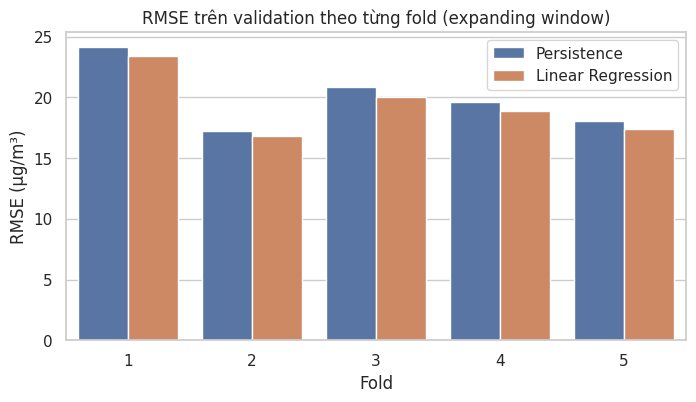

In [9]:
# --- Train so với validation của Linear Regression (kiểm tra overfit / underfit) ---
lr_val = cv_fold_metrics[cv_fold_metrics["model"] == "Linear Regression"].set_index("fold")
gap = train_metrics.set_index("fold").join(lr_val[["mae", "rmse", "r2"]].add_prefix("val_"))
gap["rmse_val_trừ_train"] = gap["val_rmse"] - gap["train_rmse"]
display(gap[["train_rmse", "val_rmse", "rmse_val_trừ_train", "train_r2", "val_r2"]])

# --- Biểu đồ RMSE theo fold ---
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=cv_fold_metrics[cv_fold_metrics["model"].isin(MAIN_MODELS)],
            x="fold", y="rmse", hue="model", ax=ax)
ax.set_title("RMSE trên validation theo từng fold (expanding window)")
ax.set_xlabel("Fold")
ax.set_ylabel("RMSE (µg/m³)")
ax.legend(title="")
save_fig(fig, "baseline_cv_rmse_by_fold")
plt.show()

### Nhận xét kết quả CV

> Số liệu dưới đây là kết quả khi chạy notebook với scikit-learn 1.8 / pandas 3.0. Nếu bạn chạy ra số hơi khác (khác phiên bản thư viện), hãy sửa lại cho khớp trước khi đưa vào báo cáo.

1. **Persistence là mốc rất mạnh.** RMSE trung bình 19.97 µg/m³, R² ≈ 0.93. PM2.5 giờ kế tiếp phần lớn giống giờ hiện tại, nên một mô hình chỉ có giá trị khi thắng được mốc này.
2. **Linear Regression thắng persistence về RMSE nhưng thua về MAE.** RMSE 19.30 (giảm khoảng 3.4%), R² 0.936; nhưng MAE 10.74 so với 10.42 (cao hơn khoảng 3.0%). Cả hai chiều này đúng ở **cả 5 fold**. Lý do hợp lý: hồi quy tuyến tính tối thiểu hóa *bình phương* sai số nên ưu tiên giảm các sai số lớn (đợt ô nhiễm), đổi lại sai số nhỏ ở mức PM2.5 thấp có thể tăng. Proposal chọn mô hình theo RMSE nên Linear Regression là baseline tốt hơn, nhưng mức cải thiện **nhỏ**, hãy báo cáo đúng như vậy.
3. **Độ lệch chuẩn giữa các fold khá lớn** (RMSE của Linear Regression từ 16.8 đến 23.4) vì mỗi fold validation rơi vào một giai đoạn/mùa khác nhau, không phải do mô hình bất ổn. Khi so hai mô hình, hãy so **trên cùng fold** (như bảng trên) thay vì so với độ lệch chuẩn.
4. **Clip về 0** giúp một chút (RMSE 19.22); khoảng 2.7% dự đoán của Linear Regression là số âm.
5. **Train so với validation:** RMSE train khoảng 19.7–21.5, cùng cỡ với validation, và chênh lệch đổi dấu giữa các fold, nên **không thấy dấu hiệu overfit**. Vì sai số train cũng cao nên giới hạn có vẻ đến từ dạng tuyến tính của mô hình (nghiêng về underfitting). Đây mới là giả thuyết, cần mô hình cây ở notebook 03 để kiểm chứng. (So train với validation theo từng fold còn bị lẫn yếu tố giai đoạn thời gian.)

## 8. Phân tích sai số trên dự đoán out-of-fold

Từ đây ta dùng bảng `oof` (dự đoán của cả 5 fold validation gộp lại, khoảng 300 nghìn dòng) để trả lời CH3 của proposal: *sai số thay đổi thế nào theo trạm, theo mùa và trong các đợt ô nhiễm cao?*

Tất cả đều là dữ liệu validation, **không dùng test**.

In [10]:
# Thêm cột phân nhóm (dùng thời điểm của nhãn)
oof["season"] = pd.Categorical(oof["target_datetime"].dt.month.map(SEASON_MAP), categories=SEASON_ORDER, ordered=True)
oof["level"] = pd.cut(oof["y_true"], bins=LEVEL_BINS, labels=LEVEL_LABELS, right=False)
oof["month"] = oof["target_datetime"].dt.to_period("M")
for key, name in MODEL_NAMES.items():
    oof[f"res_{key}"] = oof["y_true"] - oof[key]          # residual = thực tế - dự đoán

PRED_ALL = {name: key for key, name in MODEL_NAMES.items()}
PRED_MAIN = {name: key for key, name in MODEL_NAMES.items() if name in MAIN_MODELS}

# --- 8.1 Tổng thể (gộp mọi fold) ---
overall = pd.DataFrame({name: regression_metrics(oof["y_true"], oof[key]) for name, key in PRED_ALL.items()}).T
overall["mean_residual"] = [float(oof[f"res_{key}"].mean()) for key in PRED_ALL.values()]
overall["tỷ lệ dự đoán âm"] = [float((oof[key] < 0).mean()) for key in PRED_ALL.values()]
print("Tổng thể trên toàn bộ dự đoán out-of-fold:")
display(overall)

Tổng thể trên toàn bộ dự đoán out-of-fold:


,mae,rmse,r2,mean_residual,tỷ lệ dự đoán âm
Persistence,10.428,20.123,0.936,0.034,0.000
Linear Regression,10.742,19.445,0.940,0.392,0.027
Linear Regression (clip at 0),10.636,19.373,0.941,0.286,0.000


### 8.2 Theo trạm

In [11]:
by_station = metrics_by_group(oof, "station", PRED_MAIN)
t = wide(by_station, "station", "rmse")[MAIN_MODELS].copy()
t["Giảm RMSE so với persistence (%)"] = (1 - t["Linear Regression"] / t["Persistence"]) * 100
t["MAE: Persistence"] = wide(by_station, "station", "mae")["Persistence"]
t["MAE: Linear Regression"] = wide(by_station, "station", "mae")["Linear Regression"]
t = t.rename(columns={"Persistence": "RMSE: Persistence", "Linear Regression": "RMSE: Linear Regression"})
display(t)

model,RMSE: Persistence,RMSE: Linear Regression,Giảm RMSE so với persistence (%),MAE: Persistence,MAE: Linear Regression
station,,,,,
Aotizhongxin,20.704,19.960,3.595,10.586,10.878
Changping,21.232,20.618,2.893,10.335,10.753
Dingling,19.048,18.881,0.875,8.747,9.541
Dongsi,20.420,19.619,3.920,10.985,11.270
Guanyuan,18.782,18.200,3.102,10.358,10.696
Gucheng,21.053,20.259,3.774,10.795,11.126
Huairou,17.828,17.551,1.554,9.066,9.513
Nongzhanguan,20.932,20.057,4.178,10.980,11.073
Shunyi,20.713,19.701,4.885,10.913,10.914


### 8.3 Theo mùa

In [12]:
by_season = metrics_by_group(oof, "season", PRED_MAIN)
t = pd.concat({m: wide(by_season, "season", m)[MAIN_MODELS] for m in ["rmse", "mae", "r2"]}, axis=1)
display(t)
print("PM2.5 trung bình thực tế theo mùa (µg/m³):")
display(oof.groupby("season", observed=True)["y_true"].mean().rename("PM2.5 trung bình").to_frame())

PM2.5 trung bình thực tế theo mùa (µg/m³):


rmse                           mae                            r2                  
model  Persistence Linear Regression Persistence Linear Regression Persistence Linear Regression
season                                                                                          
Xuân        19.496            19.023      10.544            10.999       0.916             0.920
Hè          14.224            13.987       8.410             8.673       0.913             0.915
Thu         18.047            17.379       9.858            10.348       0.956             0.960
Đông        26.615            25.481      12.882            12.947       0.934             0.940

,PM2.5 trung bình
season,
Xuân,74.879
Hè,60.694
Thu,84.585
Đông,92.190


### 8.4 Theo mức PM2.5 thực tế (và nhóm "giờ PM2.5 cao")

Cột `mean_residual` rất quan trọng ở đây: nếu **dương** ở nhóm cao, mô hình đang **dự đoán thấp hơn** thực tế đúng lúc ô nhiễm nặng, đây chính là trường hợp cảnh báo sớm cần nhất.

In [13]:
by_level = metrics_by_group(oof, "level", PRED_MAIN)
t = pd.concat({m: wide(by_level, "level", m)[MAIN_MODELS] for m in ["mae", "rmse", "mean_residual"]}, axis=1)
t.insert(0, "n", wide(by_level, "level", "n")["Persistence"])
display(t)

high = oof[oof["y_true"] >= HIGH_THRESHOLD]
print(f"\nNhóm giờ PM2.5 cao (thực tế ≥ {HIGH_THRESHOLD}): {len(high):,} dòng ({len(high) / len(oof):.1%} tổng OOF)")
display(pd.DataFrame({name: regression_metrics(high["y_true"], high[key]) for name, key in PRED_ALL.items()}).T
        .assign(mean_residual=[float(high[f"res_{k}"].mean()) for k in PRED_ALL.values()]))


Nhóm giờ PM2.5 cao (thực tế ≥ 150): 43,920 dòng (14.6% tổng OOF)


n         mae                          rmse                   mean_residual                  
model           Persistence Linear Regression Persistence Linear Regression   Persistence Linear Regression
level                                                                                                      
0–35     112846       5.533             6.857      12.410            12.527        -1.790            -1.341
35–75     72798       9.788             9.662      16.864            16.093        -0.897            -2.895
75–115    46434      12.224            11.432      19.436            18.000         0.627            -0.454
115–150   24698      14.324            13.387      22.649            20.830         1.939             2.114
150–250   30572      17.459            16.918      27.674            25.916         3.110             6.398
>250      13348      25.737            28.047      47.453            48.064         7.901            18.981

,mae,rmse,r2,mean_residual
Persistence,19.975,34.892,0.814,4.566
Linear Regression,20.300,34.199,0.821,10.222
Linear Regression (clip at 0),20.300,34.197,0.821,10.222


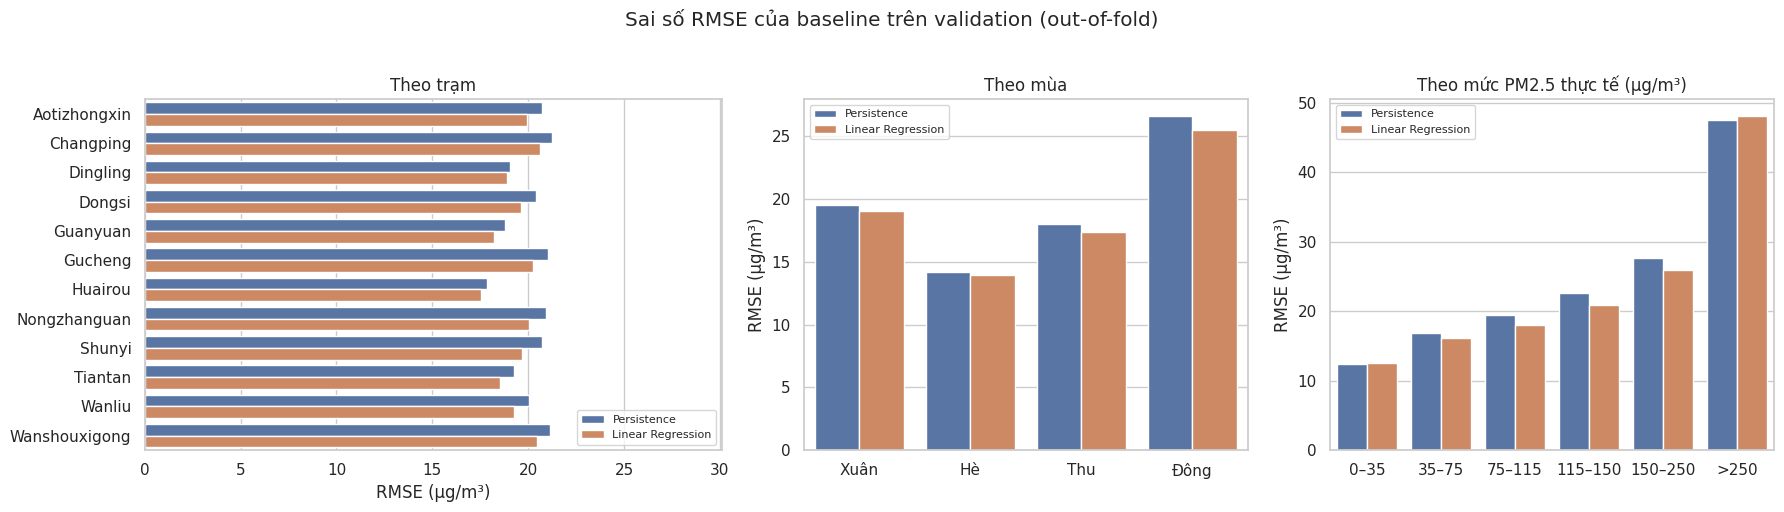

In [14]:
# --- Biểu đồ sai số theo trạm / mùa / mức ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1.3, 1, 1]})
plot_data = [
    (by_station, "station", "Theo trạm"),
    (by_season, "season", "Theo mùa"),
    (by_level, "level", "Theo mức PM2.5 thực tế (µg/m³)"),
]
for ax, (tbl, col, title) in zip(axes, plot_data):
    if col == "station":
        sns.barplot(data=tbl, y=col, x="rmse", hue="model", ax=ax)
        ax.set_xlabel("RMSE (µg/m³)"); ax.set_ylabel("")
    else:
        sns.barplot(data=tbl, x=col, y="rmse", hue="model", ax=ax)
        ax.set_ylabel("RMSE (µg/m³)"); ax.set_xlabel("")
    ax.set_title(title)
    if col == "station":
        ax.set_xlim(0, ax.get_xlim()[1] * 1.35)   # chừa chỗ cho chú thích, không đè lên cột
        ax.legend(title="", fontsize=8, loc="lower right")
    else:
        ax.legend(title="", fontsize=8, loc="upper left")
fig.suptitle("Sai số RMSE của baseline trên validation (out-of-fold)", y=1.02)
fig.tight_layout()
save_fig(fig, "baseline_error_by_group")
plt.show()

### Nhận xét theo trạm / mùa / mức PM2.5

- **Theo trạm:** Linear Regression giảm RMSE so với persistence ở cả 12 trạm (từ khoảng 0.9% ở Dingling đến 4.9% ở Shunyi). RMSE giữa các trạm khá gần nhau (khoảng 17.6–20.6 µg/m³ với Linear Regression; Huairou thấp nhất). MAE của persistence thấp hơn hoặc bằng Linear Regression ở cả 12 trạm.
- **Theo mùa:** mùa đông khó dự đoán nhất (RMSE 25.5 với Linear Regression, 26.6 với persistence; PM2.5 trung bình 92.2 µg/m³), mùa hè dễ nhất (RMSE khoảng 14). Linear Regression có RMSE thấp hơn ở cả 4 mùa, còn MAE của persistence thấp hơn ở cả 4 mùa. Tập test (09/2016–02/2017) chủ yếu là thu–đông nên số test sẽ **cao hơn** số CV.
- **Theo mức PM2.5:** sai số tăng nhanh theo mức, RMSE khoảng 12.5 ở mức 0–35 và khoảng 48 ở mức >250. Persistence tốt hơn ở mức thấp (MAE 5.5 so với 6.9 ở mức 0–35); Linear Regression tốt hơn ở mức 35–250; ở mức >250 cả hai đều sai nhiều và Linear Regression không còn lợi thế (MAE 28.0 so với 25.7).
- **Dự đoán thấp hơn thực tế ở đợt ô nhiễm nặng:** residual trung bình **dương** và tăng theo mức, rõ nhất với Linear Regression (+6.4 ở mức 150–250 và +19.0 ở mức >250; persistence lần lượt +3.1 và +7.9). Nhóm "giờ PM2.5 cao" (≥150, chiếm 14.6% số dòng OOF) có RMSE khoảng 34.2 (Linear Regression) và 34.9 (persistence), tức gấp khoảng 1.8 lần RMSE tổng thể (19.4). Đây là điểm yếu quan trọng nhất của baseline và là chỗ mô hình cây cần cải thiện.

## 9. Residual và dự đoán so với thực tế

Ba góc nhìn:

1. **Dự đoán vs thực tế** (hexbin, thang log của số điểm): điểm lý tưởng nằm trên đường chéo.
2. **Phân bố residual và residual trung bình theo mức PM2.5**: có thiên lệch hệ thống không?
3. **Chuỗi thời gian ví dụ** quanh đỉnh ô nhiễm lớn nhất trong vùng validation: nhìn trực quan persistence "chậm một nhịp" ra sao.

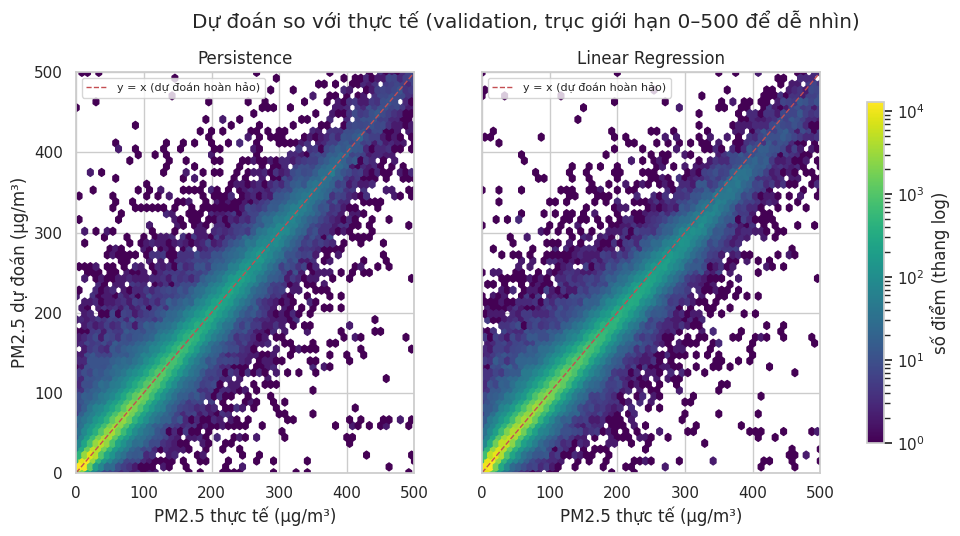

In [15]:
# --- 9.1 Dự đoán vs thực tế ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharex=True, sharey=True)
for ax, name in zip(axes, MAIN_MODELS):
    key = PRED_ALL[name]
    hb = ax.hexbin(oof["y_true"], oof[key], gridsize=60, extent=(0, 500, 0, 500), bins="log", mincnt=1, cmap="viridis")
    ax.plot([0, 500], [0, 500], "r--", lw=1, label="y = x (dự đoán hoàn hảo)")
    ax.set_title(name)
    ax.set_xlabel("PM2.5 thực tế (µg/m³)")
    ax.set_xlim(0, 500); ax.set_ylim(0, 500)
    ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("PM2.5 dự đoán (µg/m³)")
fig.colorbar(hb, ax=axes, label="số điểm (thang log)", shrink=0.85)
fig.suptitle("Dự đoán so với thực tế (validation, trục giới hạn 0–500 để dễ nhìn)", y=1.0)
save_fig(fig, "baseline_pred_vs_actual")
plt.show()

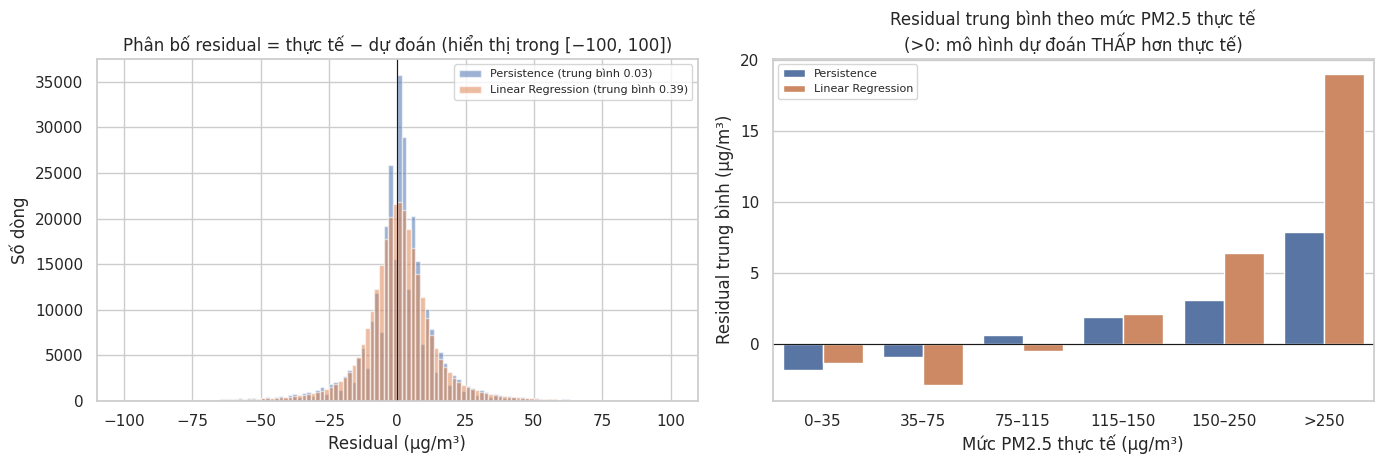

In [16]:
# --- 9.2 Phân bố residual và residual trung bình theo mức ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

for name in MAIN_MODELS:
    res = oof[f"res_{PRED_ALL[name]}"]
    axes[0].hist(res, bins=120, range=(-100, 100), alpha=0.55, label=f"{name} (trung bình {res.mean():.2f})")
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_title("Phân bố residual = thực tế − dự đoán (hiển thị trong [−100, 100])")
axes[0].set_xlabel("Residual (µg/m³)")
axes[0].set_ylabel("Số dòng")
axes[0].legend(fontsize=8)

sns.barplot(data=by_level, x="level", y="mean_residual", hue="model", ax=axes[1])
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_title("Residual trung bình theo mức PM2.5 thực tế\n(>0: mô hình dự đoán THẤP hơn thực tế)")
axes[1].set_xlabel("Mức PM2.5 thực tế (µg/m³)")
axes[1].set_ylabel("Residual trung bình (µg/m³)")
axes[1].legend(title="", fontsize=8)
fig.tight_layout()
save_fig(fig, "baseline_residuals")
plt.show()

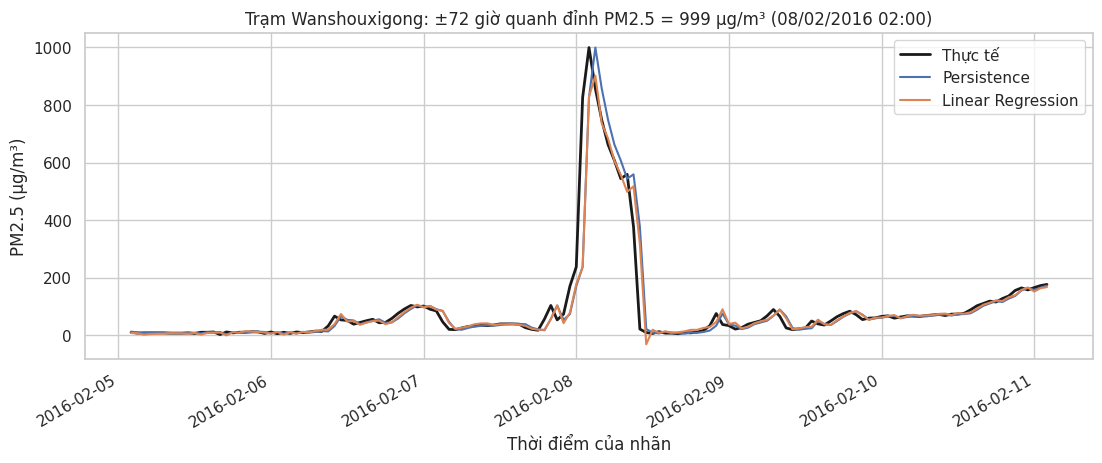

In [17]:
# --- 9.3 Chuỗi thời gian quanh đỉnh ô nhiễm lớn nhất của fold cuối ---
last = oof[oof["fold"] == oof["fold"].max()]
peak = last.loc[last["y_true"].idxmax()]
window = last[(last["station"] == peak["station"])
              & last["target_datetime"].between(peak["target_datetime"] - pd.Timedelta(hours=72),
                                                peak["target_datetime"] + pd.Timedelta(hours=72))].sort_values("target_datetime")

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(window["target_datetime"], window["y_true"], color="k", lw=2, label="Thực tế")
ax.plot(window["target_datetime"], window["persistence"], lw=1.5, label="Persistence")
ax.plot(window["target_datetime"], window["linreg"], lw=1.5, label="Linear Regression")
ax.set_title(f"Trạm {peak['station']}: ±72 giờ quanh đỉnh PM2.5 = {peak['y_true']:.0f} µg/m³ "
             f"({peak['target_datetime']:%d/%m/%Y %H:%M})")
ax.set_xlabel("Thời điểm của nhãn")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
fig.autofmt_xdate()
save_fig(fig, "baseline_timeseries_example")
plt.show()

### 9.4 Sai số theo thời gian (từng tháng)

Proposal yêu cầu xem sai số "theo thời gian". Biểu đồ dưới cho RMSE theo tháng trên toàn bộ vùng validation (các tháng nằm ở những fold khác nhau, mỗi tháng chỉ được dự đoán bởi một mô hình fit trên dữ liệu trước đó).

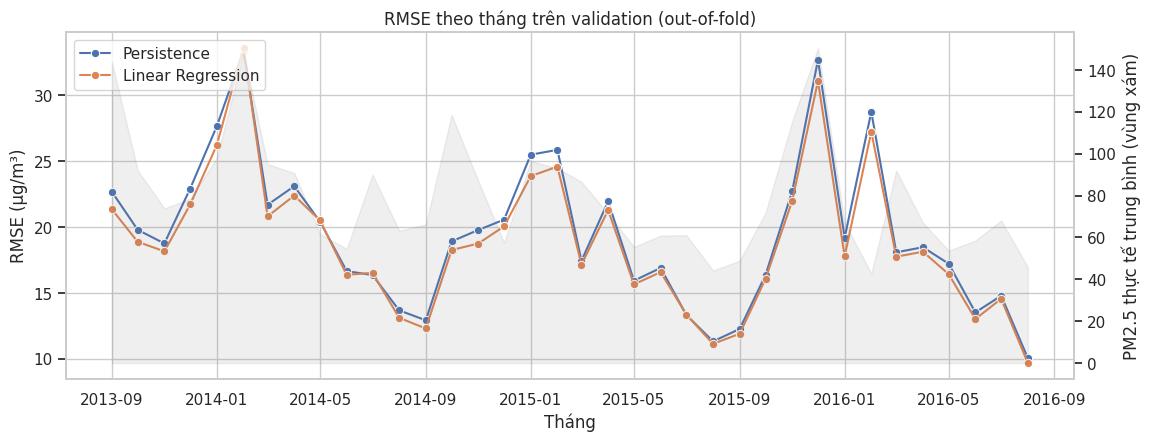

In [18]:
monthly = []
for month, g in oof.groupby("month"):
    for name in MAIN_MODELS:
        monthly.append({"month": month.to_timestamp(), "model": name, "rmse": rmse(g["y_true"], g[PRED_ALL[name]]),
                        "mean_pm25": g["y_true"].mean()})
monthly = pd.DataFrame(monthly)

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.lineplot(data=monthly, x="month", y="rmse", hue="model", marker="o", ax=ax)
ax2 = ax.twinx()
m_mean = monthly.drop_duplicates("month").set_index("month")["mean_pm25"]
ax2.fill_between(m_mean.index, m_mean.values, alpha=0.12, color="gray")
ax2.set_ylabel("PM2.5 thực tế trung bình (vùng xám)")
ax2.grid(False)
ax.set_title("RMSE theo tháng trên validation (out-of-fold)")
ax.set_xlabel("Tháng")
ax.set_ylabel("RMSE (µg/m³)")
ax.legend(title="", loc="upper left")
save_fig(fig, "baseline_rmse_by_month")
plt.show()

### Nhận xét về residual, chuỗi thời gian và sai số theo tháng

- **Residual** tập trung quanh 0 với đuôi dài: phần lớn sai số nhỏ nhưng một số ít sai số rất lớn (khoảng 0.5% dự đoán của Linear Regression lệch hơn 100 µg/m³). RMSE bị các điểm này kéo lên nhiều hơn MAE, đó cũng là lý do hai độ đo xếp hạng hai mô hình khác nhau.
- **Chuỗi thời gian ví dụ** (đợt ô nhiễm ngày 08/02/2016): persistence luôn "chậm một nhịp": khi PM2.5 tăng vọt thì dự đoán còn thấp, khi giảm nhanh sau đỉnh thì dự đoán vẫn cao. Vì chỉ có thông tin đến giờ t nên không mô hình nào "đoán trước" được bước nhảy đột ngột; mô hình tốt hơn chỉ có thể phản ứng nhanh và chính xác hơn.
- **Theo tháng:** Linear Regression có RMSE thấp hơn persistence ở 32/36 tháng validation. RMSE cao nhất ở các tháng đông–xuân (ví dụ 02/2014 ≈ 33.6, 12/2015 ≈ 31.1) và tương quan khá với PM2.5 trung bình của tháng (hệ số tương quan ≈ 0.68). Tháng 02/2016 có RMSE cao (≈ 27.2) dù PM2.5 trung bình thấp (≈ 42.8), nhiều khả năng do đợt ô nhiễm đột biến ngày 08/02/2016 (đỉnh 999, xem biểu đồ ví dụ). Giá trị 999 này đang được giữ nguyên và chờ nhóm xác minh theo nhật ký EDA, nên nếu muốn có thể làm thêm phân tích độ nhạy khi có quyết định.

## 10. Diễn giải Linear Regression

### 10.1 Hệ số của các feature số

Vì feature số đã được `StandardScaler` chuẩn hóa nên **độ lớn hệ số so sánh được với nhau** (mỗi hệ số là mức thay đổi của dự đoán, tính bằng µg/m³, khi feature tăng 1 độ lệch chuẩn).

Chỉ nên đọc hệ số của **feature số gốc**. Hệ số của các cờ missing và các cột One-Hot không nên diễn giải:

- Các cờ missing rất hiếm và khi thiếu thường thiếu **nhiều cột cùng lúc** (ví dụ các cột khí tượng), nên chúng **cộng tuyến** với nhau, khiến hệ số có thể rất lớn mà không có ý nghĩa riêng lẻ.
- One-Hot đầy đủ các cột (không bỏ một cột tham chiếu) cũng gây cộng tuyến hoàn hảo; `LinearRegression` vẫn cho nghiệm nhưng hệ số từng cột không có nghĩa tách biệt.

Đây cũng là lý do hệ số cho thấy **sự tương quan**, không phải quan hệ nhân quả: nhiều lag của PM2.5 tương quan mạnh với nhau.

Intercept (PM2.5 dự đoán khi mọi feature số bằng trung bình): 77.86
Số cờ missing có hệ số |coef| > 10: 5 / 25  (đây là lý do không diễn giải các cờ này)


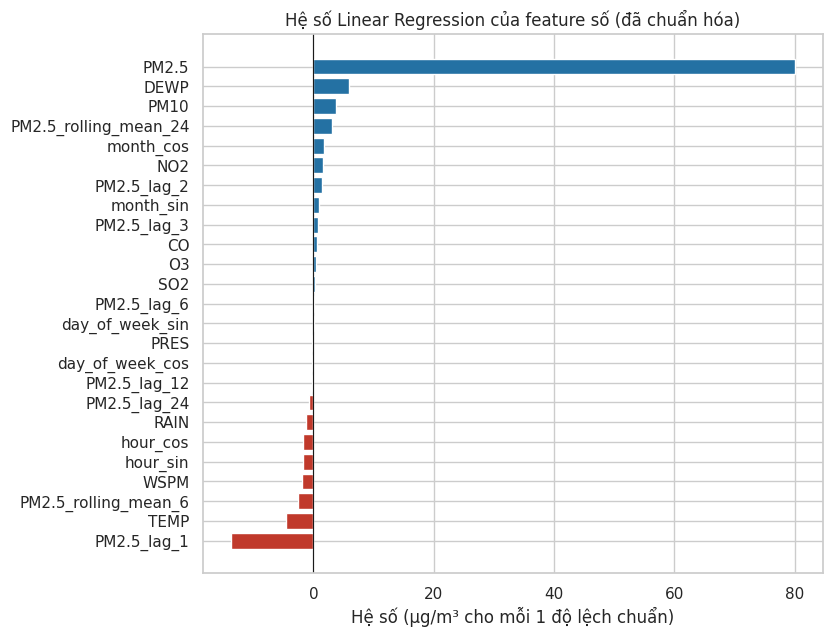

,hệ số
PM2.5,79.994
PM2.5_lag_1,-13.707
DEWP,5.871
TEMP,-4.574
PM10,3.748
PM2.5_rolling_mean_24,3.069
PM2.5_rolling_mean_6,-2.512
WSPM,-1.907


In [19]:
# Mô hình cuối (fit trên TOÀN BỘ train/validation) dùng cho diễn giải, lưu và đánh giá test
final_model = make_linear_regression().fit(X_tv, y_tv)

feature_names = final_model.named_steps["prep"].get_feature_names_out()
coef = pd.Series(final_model.named_steps["model"].coef_, index=feature_names)
numeric_coef = coef[[n.startswith("numeric__") for n in coef.index]]
numeric_coef.index = numeric_coef.index.str.replace("numeric__", "", regex=False)
numeric_coef = numeric_coef.sort_values()

print(f"Intercept (PM2.5 dự đoán khi mọi feature số bằng trung bình): {final_model.named_steps['model'].intercept_:.2f}")
print(f"Số cờ missing có hệ số |coef| > 10: {int((coef[[n.startswith('numeric_missing__') for n in coef.index]].abs() > 10).sum())}"
      f" / {sum(n.startswith('numeric_missing__') for n in coef.index)}  (đây là lý do không diễn giải các cờ này)")

fig, ax = plt.subplots(figsize=(8, 7))
colors = ["#c0392b" if v < 0 else "#2471a3" for v in numeric_coef.values]
ax.barh(numeric_coef.index, numeric_coef.values, color=colors)
ax.axvline(0, color="k", lw=0.8)
ax.set_title("Hệ số Linear Regression của feature số (đã chuẩn hóa)")
ax.set_xlabel("Hệ số (µg/m³ cho mỗi 1 độ lệch chuẩn)")
save_fig(fig, "baseline_lr_coefficients")
plt.show()
display(numeric_coef.sort_values(key=abs, ascending=False).head(8).rename("hệ số").to_frame())

### 10.2 (Tùy chọn) Permutation importance theo nhóm feature

Gợi ý cho **CH2** (*nhóm đặc trưng nào đóng góp nhiều nhất*). Ý tưởng: xáo trộn ngẫu nhiên một nhóm cột trên tập validation rồi xem RMSE **tăng** bao nhiêu; tăng càng nhiều thì mô hình càng phụ thuộc vào nhóm đó. Xáo trộn **cả nhóm cùng một hoán vị** để giữ quan hệ giữa các cột trong nhóm.

Dùng mô hình của fold cuối (fit chỉ trên train của fold đó) và một mẫu 30.000 dòng validation của fold đó. Đây là đánh giá cho **mô hình tuyến tính**; bạn thành viên phụ trách phân tích cuối sẽ lặp lại cho mô hình cây.

RMSE gốc trên mẫu validation (fold 5): 17.76


,rmse_tăng_tb,rmse_tăng_std
nhóm feature,,
PM2.5 hiện tại (t),74.776,0.115
PM2.5 lag & rolling,5.047,0.036
Khí tượng (gồm hướng gió),1.375,0.015
Chất ô nhiễm khác,0.905,0.017
Thời gian (sin/cos),0.623,0.027
Trạm,0.012,0.004


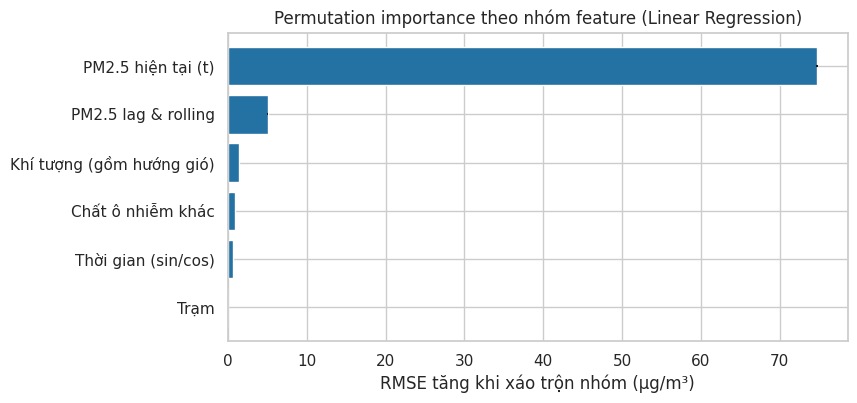

In [20]:
FEATURE_GROUPS = {
    "PM2.5 hiện tại (t)": ["PM2.5"],
    "PM2.5 lag & rolling": [c for c in FEATURE_COLUMNS if c.startswith("PM2.5_")],
    "Chất ô nhiễm khác": ["PM10", "SO2", "NO2", "CO", "O3"],
    "Khí tượng (gồm hướng gió)": ["TEMP", "PRES", "DEWP", "RAIN", "WSPM", "wd"],
    "Thời gian (sin/cos)": [c for c in FEATURE_COLUMNS if c.endswith(("_sin", "_cos"))],
    "Trạm": ["station"],
}
assert sorted(sum(FEATURE_GROUPS.values(), [])) == sorted(FEATURE_COLUMNS), "Nhóm feature chưa phủ đủ cột"


def group_permutation_importance(model, X, y, groups, n_repeats=5, seed=RANDOM_STATE):
    # Mức tăng RMSE khi xáo trộn từng nhóm cột (cả nhóm dùng chung một hoán vị).
    rng = np.random.default_rng(seed)
    base = rmse(y, model.predict(X))
    rows = []
    for name, cols in groups.items():
        increases = []
        for _ in range(n_repeats):
            shuffled = X[cols].iloc[rng.permutation(len(X))]
            shuffled.index = X.index
            X_perm = X.copy()
            X_perm[cols] = shuffled
            increases.append(rmse(y, model.predict(X_perm)) - base)
        rows.append({"nhóm feature": name, "rmse_tăng_tb": np.mean(increases), "rmse_tăng_std": np.std(increases)})
    return base, pd.DataFrame(rows).sort_values("rmse_tăng_tb", ascending=False)


last_tr, last_va = folds[-1]
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = np.sort(rng.choice(last_va, size=min(30_000, len(last_va)), replace=False))
X_s, y_s = X_tv.iloc[sample_idx].reset_index(drop=True), y_tv.iloc[sample_idx].reset_index(drop=True)

base_rmse, perm_table = group_permutation_importance(cv_models[-1], X_s, y_s, FEATURE_GROUPS)
print(f"RMSE gốc trên mẫu validation (fold 5): {base_rmse:.2f}")
display(perm_table.set_index("nhóm feature"))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(perm_table["nhóm feature"][::-1], perm_table["rmse_tăng_tb"][::-1], xerr=perm_table["rmse_tăng_std"][::-1], color="#2471a3")
ax.set_title("Permutation importance theo nhóm feature (Linear Regression)")
ax.set_xlabel("RMSE tăng khi xáo trộn nhóm (µg/m³)")
save_fig(fig, "baseline_lr_permutation_importance")
plt.show()

### Nhận xét về hệ số và permutation importance

- **PM2.5 ở giờ hiện tại áp đảo**: hệ số lớn nhất (≈ +80 trên mỗi độ lệch chuẩn), kế đến là `PM2.5_lag_1` với hệ số **âm** (≈ −14). Hai hệ số này đi cùng nhau nghĩa là mô hình không chỉ lặp lại giá trị hiện tại mà còn dùng **xu hướng** (PM2.5 đang tăng hay giảm so với 1 giờ trước). Đây là diễn giải tương quan, không phải quan hệ nhân quả.
- **Permutation importance theo nhóm** (fold cuối, RMSE gốc ≈ 17.8): xáo trộn PM2.5(t) làm RMSE tăng khoảng 75 µg/m³; nhóm lag/rolling tăng khoảng 5.0; khí tượng khoảng 1.4; chất ô nhiễm khác khoảng 0.9; thời gian khoảng 0.6; trạm gần như bằng 0 (≈ 0.01). Gợi ý trả lời sơ bộ cho **CH2** với mô hình tuyến tính: thông tin PM2.5 gần đây quyết định gần hết độ chính xác, khí tượng đóng góp nhỏ nhưng lớn hơn các chất ô nhiễm khác.
- **Thận trọng:** các feature tương quan với nhau (ví dụ PM10 với PM2.5) nên khi xáo trộn riêng một nhóm, nhóm khác bù lại một phần, vì vậy mức đóng góp của nhóm phụ có thể bị đánh giá thấp. Kết quả này chỉ áp dụng cho **mô hình tuyến tính**; cần lặp lại cho mô hình cây.

## 11. Đánh giá trên tập test (chạy một lần)

> ⚠️ **Quy tắc:** test chỉ dùng để báo cáo cuối. Baseline này **không có siêu tham số nào chọn dựa trên test** (persistence không có tham số; Linear Regression không có gì để tinh chỉnh), nên chạy ở đây không gây rò rỉ. Nhưng **sau khi xem số test không được quay lại sửa baseline** để làm đẹp kết quả.

Mô hình cuối `final_model` đã được fit trên **toàn bộ** train/validation ở mục 10 (không có dữ liệu test). Persistence dùng median target của toàn bộ train/validation làm giá trị dự phòng.

Cờ `RUN_FINAL_TEST` ở mục 1 điều khiển ô này.

In [21]:
test_table, test_by_month = None, None
if RUN_FINAL_TEST:
    fallback_full = float(y_tv.median())
    pred_persist_test, n_fb_test = predict_persistence(X_test, fallback_full)
    pred_lr_test = final_model.predict(X_test)
    test_preds = {"Persistence": pred_persist_test, "Linear Regression": pred_lr_test,
                  "Linear Regression (clip at 0)": np.clip(pred_lr_test, 0, None)}

    test_table = pd.DataFrame({name: regression_metrics(y_test, p) for name, p in test_preds.items()}).T
    print(f"Số dòng test phải dùng giá trị dự phòng của persistence: {n_fb_test} / {len(X_test):,}")
    print("Kết quả trên tập test:")
    display(test_table.sort_values("rmse"))

    pc, lc = test_table.loc["Persistence"], test_table.loc["Linear Regression"]
    print(f"RMSE test: Persistence {pc['rmse']:.2f} -> Linear Regression {lc['rmse']:.2f} (giảm {(1 - lc['rmse'] / pc['rmse']) * 100:.1f}%)")

    # Sai số theo tháng trong test + so sánh phân phối với validation
    test_eval = test[["station", "target_datetime"]].reset_index(drop=True).assign(
        y_true=y_test.to_numpy(), persistence=pred_persist_test, linreg=pred_lr_test)
    test_eval["month"] = test_eval["target_datetime"].dt.to_period("M").astype(str)
    test_by_month = metrics_by_group(test_eval, "month", PRED_MAIN)
    monthly_test = pd.concat({m: wide(test_by_month, "month", m)[MAIN_MODELS] for m in ["rmse", "mae"]}, axis=1)
    monthly_test[("PM2.5 thực tế tb", "")] = test_eval.groupby("month")["y_true"].mean()
    display(monthly_test)
    print(f"PM2.5 trung bình: validation (OOF) {oof['y_true'].mean():.1f} | test {y_test.mean():.1f} µg/m³")
else:
    print("RUN_FINAL_TEST = False: bỏ qua đánh giá test.")

Số dòng test phải dùng giá trị dự phòng của persistence: 33 / 51,063
Kết quả trên tập test:
RMSE test: Persistence 23.11 -> Linear Regression 21.80 (giảm 5.7%)
PM2.5 trung bình: validation (OOF) 77.8 | test 92.2 µg/m³


,mae,rmse,r2
Linear Regression (clip at 0),11.287,21.746,0.952
Linear Regression,11.351,21.803,0.951
Persistence,11.586,23.113,0.945


rmse                           mae                   PM2.5 thực tế tb
model   Persistence Linear Regression Persistence Linear Regression                 
month                                                                               
2016-09      12.456            12.578       7.347             7.786           54.125
2016-10      15.979            15.374       8.915             9.147           84.181
2016-11      20.832            19.294      11.946            11.225           97.482
2016-12      29.205            27.160      15.751            14.918          129.192
2017-01      32.159            30.525      15.272            14.764          113.301
2017-02      20.567            19.271       9.705             9.763           69.305

### Nhận xét kết quả test

- Trên test, Linear Regression thắng persistence ở **cả ba độ đo**: RMSE 21.80 so với 23.11 (giảm khoảng 5.7%), MAE 11.35 so với 11.59, R² 0.951 so với 0.945. Khác với CV, ở đây MAE của Linear Regression cũng thấp hơn.
- **Số test cao hơn số CV** (RMSE 21.8 so với 19.3) vì test nằm trong thu–đông với PM2.5 trung bình 92.2 µg/m³ (validation: 77.8). Theo tháng, RMSE lớn nhất vào 12/2016–01/2017 (khoảng 27–32), nơi PM2.5 trung bình trên 110 µg/m³.
- **Lợi thế của Linear Regression phụ thuộc vào mức ô nhiễm**: ở các tháng PM2.5 cao nó thắng persistence rõ hơn, còn ở tháng 09/2016 (PM2.5 trung bình thấp, khoảng 54) persistence nhỉnh hơn một chút (RMSE 12.46 so với 12.58). Điều này nhất quán với phân tích theo mức ở mục 8 và là lý do nên báo cáo cả theo tháng/mùa chứ không chỉ một con số tổng.
- Đây là mốc để các mô hình ở notebook 03 so sánh: **RMSE test 21.80 (Linear Regression) / 23.11 (persistence)**; **RMSE CV 19.30 / 19.97**.

## 12. Lưu mô hình, bảng kết quả và nhật ký thực nghiệm

- **`models/baseline_linear_regression.joblib`**: cả pipeline (tiền xử lý + Linear Regression). Nạp lại bằng `joblib.load(...)` rồi gọi `.predict(X)` với `X` có đúng các cột của `FEATURE_COLUMNS`.
- **`models/baseline_metrics.csv`**: bảng tóm tắt dạng gọn.
- **`outputs/baseline_error_analysis.csv`**: sai số theo trạm/mùa/mức.
- **`experiment_log.csv`**: thêm dòng cho từng baseline. Mỗi dòng có `experiment_id` cố định nên chạy lại notebook sẽ **ghi đè** dòng cũ thay vì thêm bản trùng. Với dòng CV, `mae/rmse/r2` là **trung bình 5 fold validation**.
- Persistence không có tham số nào học từ dữ liệu nên không có tệp mô hình; cách tính nằm trong hàm `predict_persistence`.

In [22]:
# --- Bảng tóm tắt gọn (CV validation + test) ---
summary_rows = []
for name in MODEL_NAMES.values():
    r = cv_summary.loc[name]
    summary_rows.append({"model": name, "split": "cv_validation_mean_5fold",
                         "mae": r["mae_mean"], "rmse": r["rmse_mean"], "r2": r["r2_mean"],
                         "mae_std": r["mae_std"], "rmse_std": r["rmse_std"], "r2_std": r["r2_std"],
                         "n_rows": len(oof)})
if test_table is not None:
    for name, r in test_table.iterrows():
        summary_rows.append({"model": name, "split": "test", "mae": r["mae"], "rmse": r["rmse"], "r2": r["r2"],
                             "mae_std": np.nan, "rmse_std": np.nan, "r2_std": np.nan, "n_rows": len(X_test)})
baseline_metrics = pd.DataFrame(summary_rows).round(4)
display(baseline_metrics)

# --- Bảng phân tích sai số dạng dài ---
error_analysis = pd.concat([
    by_station.rename(columns={"station": "group"}).assign(group_type="station"),
    by_season.rename(columns={"season": "group"}).assign(group_type="season"),
    by_level.rename(columns={"level": "group"}).assign(group_type="pm25_level"),
], ignore_index=True)
error_analysis["group"] = error_analysis["group"].astype(str)
error_analysis = error_analysis[["group_type", "group", "model", "n", "mae", "rmse", "r2", "mean_residual"]].round(4)


# --- Nhật ký thực nghiệm ---
LOG_COLUMNS = ["experiment_id", "model_name", "dataset_version", "mae", "rmse", "r2", "notes"]
DATASET_VERSION = (f"beijing_air_quality_standardized.csv; ffill<={FFILL_LIMIT}h; "
                   f"lags={'/'.join(map(str, PM25_LAGS))}; rolling={'/'.join(map(str, ROLLING_WINDOWS))}")


def log_experiment(new_rows):
    # Thêm/ghi đè dòng trong experiment_log.csv theo experiment_id.
    new_df = pd.DataFrame(new_rows, columns=LOG_COLUMNS)
    if EXPERIMENT_LOG.exists() and EXPERIMENT_LOG.stat().st_size > 0:
        old = pd.read_csv(EXPERIMENT_LOG)
        old = old[~old["experiment_id"].isin(new_df["experiment_id"])]
        log = new_df if old.empty else pd.concat([old, new_df], ignore_index=True)
    else:
        log = new_df
    log.to_csv(EXPERIMENT_LOG, index=False)
    return log


log_rows = []
for key, exp_name in [("Persistence", "persistence"), ("Linear Regression", "linreg")]:
    r = cv_summary.loc[key]
    log_rows.append({"experiment_id": f"baseline_{exp_name}_cv5", "model_name": key, "dataset_version": DATASET_VERSION,
                     "mae": round(r["mae_mean"], 4), "rmse": round(r["rmse_mean"], 4), "r2": round(r["r2_mean"], 4),
                     "notes": "Mean of 5 validation folds (TimeSeriesSplit, expanding window)."})
    if test_table is not None:
        r = test_table.loc[key]
        log_rows.append({"experiment_id": f"baseline_{exp_name}_test", "model_name": key, "dataset_version": DATASET_VERSION,
                         "mae": round(r["mae"], 4), "rmse": round(r["rmse"], 4), "r2": round(r["r2"], 4),
                         "notes": "Test set (labels from 2016-09-01); model fit on all train/validation."})
display(pd.DataFrame(log_rows))

# --- Ghi ra đĩa ---
if SAVE_ARTIFACTS:
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

    joblib.dump(final_model, MODELS_DIR / "baseline_linear_regression.joblib", compress=3)
    baseline_metrics.to_csv(MODELS_DIR / "baseline_metrics.csv", index=False)
    error_analysis.to_csv(OUTPUTS_DIR / "baseline_error_analysis.csv", index=False, encoding="utf-8-sig")  # utf-8-sig để Excel đọc đúng tiếng Việt

    metadata = {
        "model": "LinearRegression + build_preprocessor(scale=True)",
        "created_at": datetime.now().isoformat(timespec="seconds"),
        "sklearn_version": sklearn.__version__,
        "target": "PM2.5 at t+1 (same station)",
        "train_rows": int(len(X_tv)),
        "train_target_period": [str(train_validation["target_datetime"].min()), str(train_validation["target_datetime"].max())],
        "test_start": str(TEST_START),
        "feature_columns": list(FEATURE_COLUMNS),
        "cv": "TimeSeriesSplit expanding window, 5 folds, grouped by target timestamp",
        "persistence_note": "y_hat(t+1) = PM2.5(t) (forward-filled <= 6h); fallback = train median",
    }
    (MODELS_DIR / "baseline_metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")

    log = log_experiment(log_rows)
    print("Đã lưu:")
    for p in [MODELS_DIR / "baseline_linear_regression.joblib", MODELS_DIR / "baseline_metrics.csv",
              MODELS_DIR / "baseline_metadata.json", OUTPUTS_DIR / "baseline_error_analysis.csv", EXPERIMENT_LOG]:
        print("  ", p.relative_to(PROJECT_ROOT))
    print("\nexperiment_log.csv hiện có:")
    display(log)

    # Kiểm tra nạp lại mô hình: dự đoán phải trùng khớp
    reloaded = joblib.load(MODELS_DIR / "baseline_linear_regression.joblib")
    check = X_tv.iloc[:2000]
    assert np.allclose(reloaded.predict(check), final_model.predict(check)), "Mô hình nạp lại cho kết quả khác!"
    print("\nNạp lại mô hình bằng joblib: dự đoán trùng khớp, OK")
else:
    print("SAVE_ARTIFACTS = False: không ghi gì ra đĩa.")

Đã lưu:
   models/baseline_linear_regression.joblib
   models/baseline_metrics.csv
   models/baseline_metadata.json
   outputs/baseline_error_analysis.csv
   experiment_log.csv

experiment_log.csv hiện có:

Nạp lại mô hình bằng joblib: dự đoán trùng khớp, OK


,model,split,mae,rmse,r2,mae_std,rmse_std,r2_std,n_rows
0,Persistence,cv_validation_mean_5fold,10.424,19.966,0.932,1.454,2.728,0.017,300696
1,Linear Regression,cv_validation_mean_5fold,10.738,19.295,0.936,1.540,2.620,0.016,300696
2,Linear Regression (clip at 0),cv_validation_mean_5fold,10.631,19.223,0.937,1.511,2.621,0.015,300696
3,Persistence,test,11.586,23.113,0.945,NaN,NaN,NaN,51063
4,Linear Regression,test,11.351,21.803,0.951,NaN,NaN,NaN,51063
5,Linear Regression (clip at 0),test,11.287,21.746,0.952,NaN,NaN,NaN,51063


,experiment_id,model_name,dataset_version,mae,rmse,r2,notes
0,baseline_persistence_cv5,Persistence,beijing_air_quality_standardized.csv; ffill<=6h; lags=1/2/3/6/12/24; rolling=6/24,10.424,19.966,0.932,"Mean of 5 validation folds (TimeSeriesSplit, expanding window)."
1,baseline_persistence_test,Persistence,beijing_air_quality_standardized.csv; ffill<=6h; lags=1/2/3/6/12/24; rolling=6/24,11.586,23.113,0.945,Test set (labels from 2016-09-01); model fit on all train/validation.
2,baseline_linreg_cv5,Linear Regression,beijing_air_quality_standardized.csv; ffill<=6h; lags=1/2/3/6/12/24; rolling=6/24,10.738,19.295,0.936,"Mean of 5 validation folds (TimeSeriesSplit, expanding window)."
3,baseline_linreg_test,Linear Regression,beijing_air_quality_standardized.csv; ffill<=6h; lags=1/2/3/6/12/24; rolling=6/24,11.351,21.803,0.951,Test set (labels from 2016-09-01); model fit on all train/validation.


,experiment_id,model_name,dataset_version,mae,rmse,r2,notes
0,baseline_persistence_cv5,Persistence,beijing_air_quality_standardized.csv; ffill<=6h; lags=1/2/3/6/12/24; rolling=6/24,10.424,19.966,0.932,"Mean of 5 validation folds (TimeSeriesSplit, expanding window)."
1,baseline_persistence_test,Persistence,beijing_air_quality_standardized.csv; ffill<=6h; lags=1/2/3/6/12/24; rolling=6/24,11.586,23.113,0.945,Test set (labels from 2016-09-01); model fit on all train/validation.
2,baseline_linreg_cv5,Linear Regression,beijing_air_quality_standardized.csv; ffill<=6h; lags=1/2/3/6/12/24; rolling=6/24,10.738,19.295,0.936,"Mean of 5 validation folds (TimeSeriesSplit, expanding window)."
3,baseline_linreg_test,Linear Regression,beijing_air_quality_standardized.csv; ffill<=6h; lags=1/2/3/6/12/24; rolling=6/24,11.351,21.803,0.951,Test set (labels from 2016-09-01); model fit on all train/validation.


## 13. Tổng kết, hạn chế và bàn giao

### Kết luận chính (phần baseline)

1. Persistence là mốc rất mạnh vì PM2.5 liền kề tự tương quan cao (R² ≈ 0.93–0.95).
2. Linear Regression cải thiện RMSE so với persistence khoảng 3.4% (CV) và 5.7% (test) nhưng MAE gần như ngang bằng. Mức cải thiện nhỏ nên mô hình phi tuyến cần cho thấy mức cải thiện **rõ hơn** thì mới đáng kể.
3. Điểm yếu lớn của baseline: **dự đoán thấp hơn thực tế khi PM2.5 cao** (đặc biệt >250), và sai số cao nhất vào mùa đông.
4. Không thấy dấu hiệu overfit; sai số train cũng cao nên có thể mô hình tuyến tính bị hạn chế về khả năng biểu diễn.

### Hạn chế cần ghi trong báo cáo

- Persistence dùng PM2.5 đã forward-fill tối đa 6 giờ và median của train cho khoảng 0.05% dòng còn thiếu; đây là quyết định kỹ thuật chứ không phải persistence "thuần".
- Các giá trị PM2.5 rất cao (999 ở Wanshouxigong ngày 08/02/2016; 844 ở Nongzhanguan ngày 05/05/2013) đang được giữ nguyên theo nhật ký EDA; chưa có phân tích độ nhạy.
- Biến thể "clip at 0" chỉ là hậu xử lý đơn giản, không phải mô hình khác.
- Hệ số của cờ missing và One-Hot không diễn giải được (cộng tuyến).
- Sai số giữa các fold dao động nhiều do khác giai đoạn/mùa; permutation importance mục 10.2 chỉ chạy trên một fold và một mẫu 30.000 dòng.

### Bàn giao cho notebook 03 và các thành viên khác

- Dùng **cùng** `folds`, `regression_metrics` và `metrics_by_group` để so sánh công bằng; chép các hàm này sang notebook 03 (hoặc chuyển vào `src/evaluate.py` khi cả nhóm đồng ý).
- Bảng so sánh: `models/baseline_metrics.csv` và các dòng `baseline_*` trong `experiment_log.csv` (dùng cùng định dạng `experiment_id` cho các mô hình sau).
- Khi báo cáo mô hình cây, đối chiếu thêm nhóm **giờ PM2.5 cao (≥150)** và residual trung bình theo mức, vì đó là nơi baseline yếu nhất.

### Trước khi commit

1. `Restart & Run All` chạy hết không lỗi.
2. Kiểm tra các tệp mới: `models/baseline_*`, `outputs/baseline_error_analysis.csv`, `outputs/figures/baseline_*.png`, `experiment_log.csv`.
3. Cập nhật `models/README.md`, `notebooks/README.md` và `outputs/README.md` cho khớp (các README hiện ghi là chưa có mô hình/hình).